In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

## Load Data

In [40]:
# If running on colab you can download the data using gdown. Uncomment the below code. 
# import gdown
# !gdown 1hVRVEC7siG7ROyVDaEZrKjHUaWLJYaY1 #x_train_img.npz
# !gdown 1bLJrl5Dv7hi8K7-0LQtpnsF8FOPqlzIs #x_test_img.npz

In [41]:
img_file = "x_train_img.npz"
metadata_file = "x_train.csv"
y_file = "y_train.csv"

In [42]:
X_dev = pd.read_csv(metadata_file)
y_dev = pd.read_csv(y_file)
X_dev

,patient_id,img_id,age,region,itch,grew,hurt,changed,bleed,elevation
0,PAT_960,PAT_960_0001,62,NOSE,False,True,False,False,False,True
1,PAT_601,PAT_601_0002,70,FACE,True,False,True,False,True,True
2,PAT_816,PAT_816_0003,71,HAND,True,False,False,False,False,False
3,PAT_083,PAT_083_0005,36,CHEST,False,True,False,False,False,True
4,PAT_897,PAT_897_0008,71,NOSE,True,False,True,False,True,True
...,...,...,...,...,...,...,...,...,...,...
1509,PAT_467,PAT_467_1888,54,THIGH,False,True,True,False,False,True
1510,PAT_1120,PAT_1120_1889,55,BACK,False,False,False,False,False,True
1511,PAT_635,PAT_635_1890,68,ABDOMEN,True,True,False,False,False,True
1512,PAT_190,PAT_190_1892,66,FACE,True,True,False,False,True,True


In [43]:
# Function and code to load images
def load_img_data(file_path):
    with np.load(file_path, allow_pickle=True) as data:
        img = data['images']
        ids = data['image_ids']
    print(f"Successfully loaded {img.shape[0]} images.")  
    return img, ids

imgs, img_ids = load_img_data(img_file)
print(img_ids.shape, imgs.shape)

# Make sure the IDs match and are in the same order
assert np.all(img_ids == X_dev['img_id']), "Image IDs in metadata and image data do not match"

Successfully loaded 1514 images.
(1514,) (1514, 256, 256, 3)


<Axes: xlabel='count', ylabel='fine_label'>

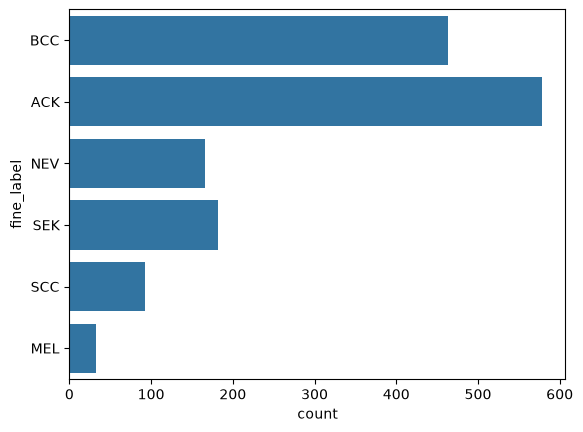

In [44]:
# Plot the class balance
sns.countplot(y_dev["fine_label"])

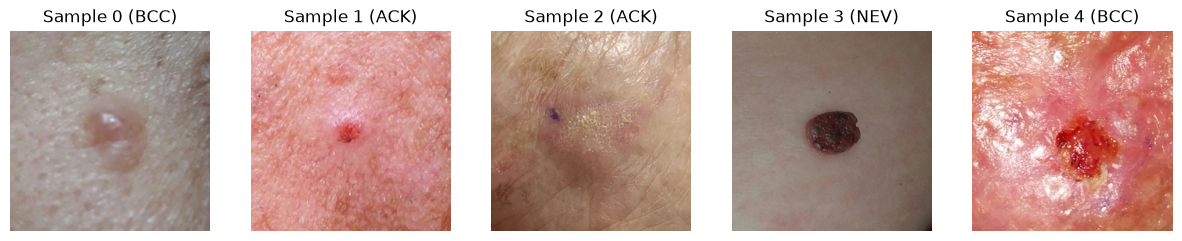

In [45]:
# Show the first 5 images
fig, axes = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    axes[i].imshow(imgs[i])
    axes[i].axis('off')
    axes[i].set_title(f"Sample {i} ({y_dev.iloc[i]["fine_label"]})")

plt.show()

## Encode Categorical Features

We'll convert all categorical features to one-hot encodings, and all binary features to 1/0. 
We can auto-detect the binary features by looking for "True" and "False" (after manually looking through the data to confirm that's how these features are encoded.) Note you'll also want to apply this code to x_test for your final predictions. 

In [46]:
# Get all obvious true/false cols that aren't already true/false
for col in X_dev.select_dtypes(include=['object']):
    if X_dev[col].dropna().astype(str).str.contains('True|False').any():
        print(f"Automatically converting {col} to binary...")
        unmapped = X_dev[~X_dev[col].isin(['True','False'])][col].unique()
        print("The following values are being mapped to NaN in this column: ", unmapped)
        X_dev[col] = X_dev[col].map({'True': 1, 'False': 0, True: 1, False: 0})

# Encode region with a one-hot encoder
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
region_dev_encoded = ohe.fit_transform(X_dev[['region']])

region_cols = ohe.get_feature_names_out(['region'])
region_dev_df = pd.DataFrame(region_dev_encoded, columns=region_cols, index=X_dev.index)
X_dev = pd.concat([X_dev.drop(columns=['region']), region_dev_df], axis=1)
print("New encoded region columns:", list(region_cols))

New encoded region columns: ['region_ABDOMEN', 'region_ARM', 'region_BACK', 'region_CHEST', 'region_EAR', 'region_FACE', 'region_FOOT', 'region_FOREARM', 'region_HAND', 'region_LIP', 'region_NECK', 'region_NOSE', 'region_SCALP', 'region_THIGH']


### Make age groups feature

In [47]:
age_groups = pd.cut(
    X_dev['age'], 
    bins=[0, 30, 60, 100], 
    labels=['Young (<30)', 'Adult (30-60)', 'Senior (60+)']
)

## Your Code

You might want to revisit the above preprocessing steps for your Problem 2 model. You also might want to put some of the above code into functions to make it easier to apply to different datasets. 

## Problem 1
Random Forest with engineered image features

Goal: teach the random forest to recognize patterns in the 8 clinical features that help it predict coarse_label
- Some data isn't in a format where the model can understand it, so we preprocess
- We need to evaluate our model with cross-validation to estimate how well it performs on data it hasn't seen

In [48]:
# Baseline random forest pipeline (using only clinical features)
# Then we can add the engineered features one at a time
# That way we can measure whether each image feature actually improves performance

# Prepare the data

# Reload the original clinical data
# Features model uses to make predictions
X = pd.read_csv(metadata_file)

# Target: 1 = requires treatment, 0 = doesn't require treatment
# Correct binary labels model learns to predict
y = y_dev['coarse_label']

# Patient IDs for grouped cross-validation
groups = X['patient_id']

# Remove identifiers from model's features (these aren't meaningful clinical features)
X = X.drop(columns=['patient_id', 'img_id'])

print("Feature shape:", X.shape)
print("\nFeature columns and types:")
print(X.dtypes)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (1514, 8)

Feature columns and types:
age           int64
region       object
itch           bool
grew           bool
hurt           bool
changed        bool
bleed          bool
elevation      bool
dtype: object

Target distribution:
coarse_label
1    1166
0     348
Name: count, dtype: int64


In [65]:
# Build preprocessing pipeline 
# Apply different preprocessing to different column types

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from sklearn.model_selection import cross_validate

### E1: Extract RGB color variation (standard deviation)

In [57]:
color_features = np.std(imgs, axis=(1, 2))
print("Color feature shape:", color_features.shape)

# Convert features into a DataFrame to make it easier to combine with existing clinical features
color_features_df = pd.DataFrame(color_features, columns=['red_std', 'green_std', 'blue_std'])
X_color = pd.concat([X.reset_index(drop=True), color_features_df], axis=1) # Combine 8 clinical features w/ 3 image features = 11 input features
print("Combined feature shape:", X_color.shape)

Color feature shape: (1514, 3)
Combined feature shape: (1514, 11)


### E2: RGB mean intensities (image's mean intensity)

In [58]:
mean_features = np.mean(imgs, axis=(1, 2))
print("Mean feature shape:", mean_features.shape)

mean_features_df = pd.DataFrame(mean_features, columns=['red_mean', 'green_mean', 'blue_mean'])
X_mean = pd.concat([X.reset_index(drop=True), mean_features_df], axis=1)
print("Combined feature shape:", X_mean.shape)

Mean feature shape: (1514, 3)
Combined feature shape: (1514, 11)


### E3: Combine STD and mean features

In [59]:
X_std_mean = pd.concat([X.reset_index(drop=True), color_features_df.reset_index(drop=True), mean_features_df.reset_index(drop=True)], axis=1)

### Preprocessing input features

In [60]:
# Identify features types
# numeric_features = ['age'] # Baseline
# numeric_features = ['age', 'red_std', 'green_std', 'blue_std'] # E1
# numeric_features = ['age', 'red_mean', 'green_mean', 'blue_mean'] # E2
numeric_features = ['age', 'red_std', 'green_std', 'blue_std', 'red_mean', 'green_mean', 'blue_mean'] # E3

categorical_features = ['region']
boolean_features = ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']

# Preprocess numerical features
# SimpleInputer: fills in missing vals so random forest can use the data
numeric_transformer = Pipeline(steps=[
  ('imputer', SimpleImputer(strategy='median'))
])

# Preprocess categorical features
# OneHotEncoder: converts region into separate binary cols
categorical_transformer = Pipeline(steps=[
  ('imputer', SimpleImputer(strategy='most_frequent')),
  ('onhot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
# passthrough: keeps bool feats as they are, forest can work with bools directly
preprocessor = ColumnTransformer(
  transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
    ('bool', 'passthrough', boolean_features)
  ]
)

### Create model pipeline

In [61]:
# Create random forest pipeline
# Use random_state=42 to make random forest's randomness reproducible
model_pipeline = Pipeline(steps=[
  ('preprocessor', preprocessor), # Takes the original clinical data + converts it to format model can use
  ('classifier', RandomForestClassifier(random_state=42)) # Receives processed data + learns patterns that predict coarse_label
])

### Set up cross-validation

In [ ]:
# Evaluate how well our model performs on unseen data
# Use at least 3 folds
# Use GroupKFold instead of KFold because some patients in dataset have multiple lesions
# Don't want model to train on one lesions from a patient and validating on another lesion from the same patient
cv = GroupKFold(n_splits=3)


### Evaluate model using AUROC

In [35]:
# Splits data into 3 patient-grouped folds, fits preprocessing using each fold's training data, trains random forest, predicts probs on val data, calcs auroc for each fold
scores = cross_val_score(model_pipeline, X_std_mean, y, groups=groups, cv=cv, scoring='roc_auc')

print("AUROC scores:", scores)
print("Mean AUROC:", scores.mean())
print("Standard deviation:", scores.std())

AUROC scores: [0.89850649 0.87374055 0.89955512]
Mean AUROC: 0.890600723063481
Standard deviation: 0.011929623544465801


### Hyperparamter search
Use GridSearchCV to systematically test different combinations of random forest hyperparameters using existing GroupKFold setup, then compare AUROC scores
For now, use the features from E3, and the same preprocessing (isolate hyperparam testing)
- n_estimators: # of trees in the forest (can make predictions more stable, but take longer to train)
- max_depth: max depth of each tree (shallower trees can help prevent overfitting)
- min_samples_leaf: min samples required in each leaf (larger leaf sizes make trees less sensitive to individual training examples)
- min_samples_split: larger vals make it harder for a node to split
- max_leaf_nodes: limits the # of terminal nodes in a tree

We will create the figure for one focused hyperparameter, and then use grid search for the rest

A hyperparameter controls model complexity if changing it affects how complicated the patterns our model can learn are (how much freedom it has to fit the training data) 

ex. max_depth: each additional level lets the tree make more specific decisions + more complex patterns
- Too shallow of a tree --> underfitting
- Too deep of a tree --> overfitting

We want to find a balance!

In [ ]:
# The hyperparameter we choose to create a figure for is max_depth
# Figure should show performance over at least 5 distinct hyperparam vals (for both underfitting + overfitting cases)

# None is clearly overfitting, 1 is clearly underfitting
max_depth_values = [1, 2, 3, 5, 6, 7, 8, 9, 10, 20, 50, 100, None]

depth_results = []

for depth in max_depth_values:
  model = clone(model_pipeline)
  model.set_params(classifier__max_depth=depth)

  scores = cross_validate(model, X_std_mean, y, groups=groups, cv=cv, scoring='roc_auc', return_train_score=True)

  for fold in range(3):
    depth_results.append({
      'max_depth': str(depth),
      'fold': fold + 1,
      'train_auroc': scores['train_score'][fold],
      'validation_auroc': scores['test_score'][fold]
    })

depth_results = pd.DataFrame(depth_results)

In [67]:
# Calculate avgs + stds
summary = depth_results.groupby('max_depth').agg(
    train_mean=('train_auroc', 'mean'),
    train_std=('train_auroc', 'std'),
    validation_mean=('validation_auroc', 'mean'),
    validation_std=('validation_auroc', 'std')
)

print(summary)

           train_mean  train_std  validation_mean  validation_std
max_depth                                                        
1            0.898901   0.009218         0.889243        0.016418
10           0.996265   0.000650         0.895317        0.012961
100          1.000000   0.000000         0.890601        0.014611
2            0.911301   0.010110         0.891624        0.013104
20           1.000000   0.000000         0.891262        0.013413
3            0.924080   0.007343         0.895268        0.014033
5            0.950038   0.004732         0.896109        0.015400
50           1.000000   0.000000         0.890601        0.014611
None         1.000000   0.000000         0.890601        0.014611


In [63]:
# Define configurations we want to test
# param_grid = {
#   'classifier__n_estimators': 
# }